# Задание № 3. Прикладные дифференциальные уравнения
Условия взяты из `Практические занятия Листок 3.pdf`. В каждой задаче есть аналитическое решение, статический рисунок (`fig/Sol_3_*.png`) и анимация.

Анимации встроены через `to_jshtml`, поэтому внизу у них есть кнопки «пуск», «пауза» и ползунок. Они работают в сохранённом ноутбуке без запущенного ядра, а виджеты `matplotlib.widgets` так работать не могут. Копии лежат в `fig/*.gif`.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq
from scipy.special import ellipk
from IPython.display import HTML, display
plt.rcParams['animation.embed_limit'] = 40
G = 9.81

def show_anim(fig, update, frames, name, interval=50):
    '''Сохраняет GIF и показывает анимацию с кнопками управления.'''
    ani = FuncAnimation(fig, update, frames=frames, interval=interval, blit=False)
    ani.save(f'fig/{name}.gif', writer=PillowWriter(fps=int(1000/interval)), dpi=60)
    html = ani.to_jshtml(default_mode='loop')
    plt.close(fig)
    return HTML(html)

## 3.1. Задача о равномерном спуске
Найти кривую, по которой тяжёлая точка опускается равномерно: $v_y=\dot y=-c=\text{const}<0$.

**Постановка.** Ось $x$ горизонтальна, ось $y$ направлена вверх. На точку действуют сила тяжести $(0,-mg)$ и реакция $\vec N$, перпендикулярная касательной $(1,y')$, то есть $\vec N=\lambda(-y',1)$.

**Второй закон Ньютона:**
$$m\ddot x=-\lambda y',\qquad m\ddot y=\lambda-mg.$$

**Исключение реакции.** Из $\ddot y=0$ следует $\lambda=mg$, поэтому $\ddot x=-gy'$. Вдоль кривой $\dot y=y'\dot x$, откуда $y'=-c/\dot x$. Получаем
$$\ddot x=\frac{gc}{\dot x}\quad\Longrightarrow\quad \dot x\,\ddot x=gc\quad\Longrightarrow\quad \dot x^2=2gct+v_0^2,$$
где $v_0=\dot x(0)$.

**Интегрирование.** При $v_0=0$ (вертикальная касательная в начальной точке) и $x(0)=x_0$, $y(0)=y_0$:
$$x-x_0=\int_0^t\sqrt{2gc\tau}\,d\tau=\frac{2\sqrt{2gc}}{3}\,t^{3/2},\qquad y_0-y=ct.$$
Исключая $t=(y_0-y)/c$, находим **полукубическую параболу**:
$$\boxed{\,y=y_0-\left(\frac{3c\,(x-x_0)}{2\sqrt{2g}}\right)^{2/3}\,},\qquad (x-x_0)^2=\frac{8g}{9c^2}(y_0-y)^3.$$
Это изохрона Лейбница. Закон сохранения энергии согласуется с решением: $\dot x^2+c^2=c^2+2g(y_0-y)$.

макс. отклонение от формулы: 1.7208456881689926e-11


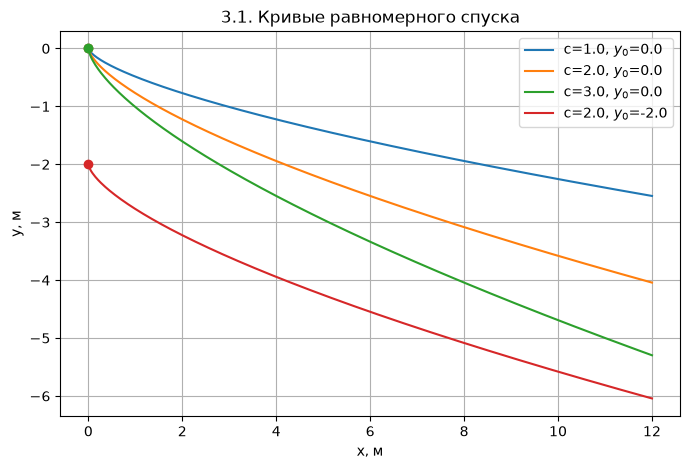

In [2]:
def descent_curve(x, c, x0=0., y0=0.):
    return y0-(3*c*(x-x0)/(2*np.sqrt(2*G)))**(2/3)

# Проверка: численно решаем ẍ = g·c/ẋ и сравниваем с формулой
c = 2.0
sol = solve_ivp(lambda t,s:[s[1],G*c/s[1]],[1e-6,3],[2*np.sqrt(2*G*c)/3*(1e-6)**1.5,np.sqrt(2*G*c*1e-6)],rtol=1e-11,atol=1e-13,dense_output=True)
tt = np.linspace(.1,3,50); xx = sol.sol(tt)[0]
print('макс. отклонение от формулы:',np.abs(descent_curve(xx,c)-(-c*tt)).max())
assert np.abs(descent_curve(xx,c)-(-c*tt)).max()<1e-6

fig,ax = plt.subplots(figsize=(8,5))
for c_,y0,col in [(1.,0.,'C0'),(2.,0.,'C1'),(3.,0.,'C2'),(2.,-2.,'C3')]:
    x = np.linspace(0,12,400)
    ax.plot(x,descent_curve(x,c_,0,y0),col,label=f'c={c_}, $y_0$={y0}')
    ax.plot(0,y0,'o',color=col)
ax.set_xlabel('x, м'); ax.set_ylabel('y, м'); ax.grid(True); ax.legend(); ax.set_title('3.1. Кривые равномерного спуска')
fig.savefig('fig/Sol_3_1.png',dpi=130,bbox_inches='tight'); plt.show()

In [3]:
c = 2.; T = 3.
tf = np.linspace(0,T,60)
xt,yt = 2*np.sqrt(2*G*c)/3*tf**1.5,-c*tf
fig,ax = plt.subplots(figsize=(6.5,4.2))
ax.plot(xt,yt,'gray'); pt, = ax.plot([],[],'ro',ms=9)
trace, = ax.plot([],[],'r',lw=2); txt = ax.text(.03,.05,'',transform=ax.transAxes)
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.grid(True); ax.set_title('Равномерный спуск')
def update(i):
    pt.set_data([xt[i]],[yt[i]]); trace.set_data(xt[:i+1],yt[:i+1])
    txt.set_text(f't={tf[i]:.2f} c  y={yt[i]:.2f}  $v_y$={-c:.2f}  $v_x$={np.sqrt(2*G*c*tf[i]):.2f}')
show_anim(fig,update,len(tf),'Sol_3_1')

## 3.2. Бильярд в прямоугольнике
**Постановка.** Область $0\leqslant x\leqslant a$, $0\leqslant y\leqslant b$. Внутри области движение свободное: $\ddot x=\ddot y=0$. На границе отражение упругое: при ударе о вертикальную стенку $v_x\to-v_x$, о горизонтальную $v_y\to-v_y$. Величины $|v_x|$, $|v_y|$ сохраняются.

**Метод развёртки.** Вместо отражения шара отражаем сам прямоугольник. Траектория становится прямой на плоскости: $X=x_0+v_xt$, $Y=y_0+v_yt$. Настоящая координата получается «складыванием»: $x=\Phi_a(X)$, где $\Phi_a(X)=a-|\,(X\bmod 2a)-a\,|$, и аналогично для $y$.

**Движение на торе.** Функция $\Phi_a$ имеет период $2a$, поэтому фазовая динамика эквивалентна равномерному движению на торе $\mathbb T^2=\mathbb R/2a\mathbb Z\times\mathbb R/2b\mathbb Z$.

**Периодичность и эргодичность.** Частоты равны $\omega_x=v_x/(2a)$, $\omega_y=v_y/(2b)$.
- Если $\dfrac{\omega_x}{\omega_y}=\dfrac{v_x\,b}{v_y\,a}=\dfrac pq\in\mathbb Q$ (несократимая дробь), траектория **периодична**. Период равен $T=2ap/|v_x|=2bq/|v_y|$.
- Если отношение иррационально, траектория **всюду плотна** на торе и равномерно распределена (теорема Кронекера—Вейля). Такое движение эргодично: среднее по времени равно среднему по тору. В конфигурационном прямоугольнике траектория плотна.

**Гамильтонова формулировка.** Внутри области $H=\dfrac{p_x^2+p_y^2}{2m}$. Уравнения Гамильтона дают $\dot x=p_x/m$, $\dot p_x=0$. Интегралы движения $p_x^2$ и $p_y^2$ независимы, поэтому система интегрируема по Лиувиллю. Переменные действие—угол: $I_x=\dfrac{a|p_x|}{\pi}$, $I_y=\dfrac{b|p_y|}{\pi}$, тогда $H=\dfrac{\pi^2}{2m}\left(\dfrac{I_x^2}{a^2}+\dfrac{I_y^2}{b^2}\right)$. Частоты $\partial H/\partial I_x=\pi|p_x|/(ma)$ задают равномерное вращение углов на торе.

развёртка совпадает с прямым моделированием


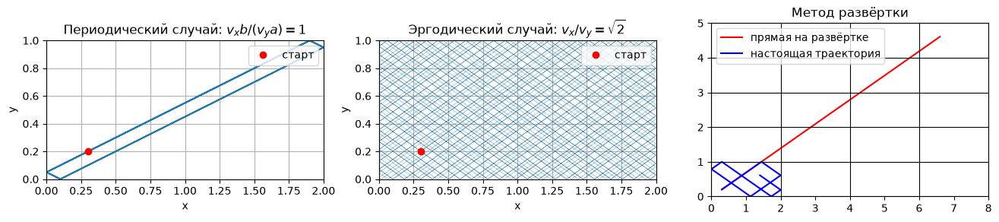

In [4]:
def fold(X, L):
    return L-np.abs(np.mod(X,2*L)-L)

def simulate_reflect(a,b,x0,y0,vx,vy,T,dt=1e-3):
    '''Прямое моделирование с отражениями — для проверки формулы развёртки.'''
    x,y = x0,y0; out=[]
    for k in range(int(T/dt)):
        x+=vx*dt; y+=vy*dt
        if x<0 or x>a: vx=-vx; x=2*(a if x>a else 0)-x
        if y<0 or y>b: vy=-vy; y=2*(b if y>b else 0)-y
        out.append((x,y))
    return np.array(out)

a,b = 2.,1.
ref = simulate_reflect(a,b,.3,.2,1.,.7,10.)
t = (np.arange(len(ref))+1)*1e-3
assert np.abs(ref[:,0]-fold(.3+t,a)).max()<1e-9 and np.abs(ref[:,1]-fold(.2+.7*t,b)).max()<1e-9
print('развёртка совпадает с прямым моделированием')

fig,axs = plt.subplots(1,3,figsize=(16,4.6))
t1 = np.linspace(0,8,4000)      # vx*b/(vy*a)=1/1 при vx=2, vy=1: периодический случай
axs[0].plot(fold(.3+1.0*t1*2,a),fold(.2+1.0*t1,b),lw=1.2)
axs[0].plot(.3,.2,'ro',label='старт'); axs[0].set_title('Периодический случай: $v_xb/(v_ya)=1$')
t2 = np.linspace(0,120,40000)
axs[1].plot(fold(.3+t2*np.sqrt(2),a),fold(.2+t2,b),lw=.25)
axs[1].plot(.3,.2,'ro',label='старт'); axs[1].set_title('Эргодический случай: $v_x/v_y=\\sqrt{2}$')
for ax in axs[:2]:
    ax.set_xlim(0,a); ax.set_ylim(0,b); ax.set_aspect('equal'); ax.set_xlabel('x'); ax.set_ylabel('y'); ax.legend(loc='upper right'); ax.grid(True)
t3 = np.linspace(0,6.3,300); X,Y = .3+t3,.2+.7*t3
axs[2].plot(X,Y,'r',label='прямая на развёртке'); axs[2].plot(fold(X,a),fold(Y,b),'b',label='настоящая траектория')
for i in range(5): axs[2].axvline(i*a,color='k',lw=.8)
for j in range(6): axs[2].axhline(j*b,color='k',lw=.8)
axs[2].set_xlim(0,8); axs[2].set_ylim(0,5); axs[2].set_aspect('equal'); axs[2].legend(loc='upper left'); axs[2].set_title('Метод развёртки')
fig.savefig('fig/Sol_3_2.png',dpi=120,bbox_inches='tight'); plt.show()

In [5]:
# Анимация: шар в прямоугольнике и та же точка на развёртке
vx,vy = 1.,.7; x0,y0 = .3,.2
tf = np.linspace(0,7,90)
fig,(a1,a2) = plt.subplots(1,2,figsize=(10,3.6))
a1.set_xlim(0,2); a1.set_ylim(0,1); a1.set_aspect('equal'); a1.set_title('Отражения'); a1.grid(True)
a2.set_xlim(0,8); a2.set_ylim(0,5); a2.set_aspect('equal'); a2.set_title('Развёртка')
for i in range(5): a2.axvline(i*2,color='k',lw=.8)
for j in range(6): a2.axhline(j*1,color='k',lw=.8)
tr1, = a1.plot([],[],'b',lw=1); p1, = a1.plot([],[],'ro'); tr2, = a2.plot([],[],'r',lw=1); p2, = a2.plot([],[],'ro')
txt = a1.text(.02,1.03,'',transform=a1.transAxes,fontsize=8)
def update(i):
    t = np.linspace(0,tf[i],max(i*6,2)); X,Y = x0+vx*t,y0+vy*t
    tr1.set_data(fold(X,2),fold(Y,1)); p1.set_data([fold(X[-1],2)],[fold(Y[-1],1)])
    tr2.set_data(X,Y); p2.set_data([X[-1]],[Y[-1]])
    txt.set_text(f't={tf[i]:.2f}')
show_anim(fig,update,len(tf),'Sol_3_2_unfold')

In [6]:
# Анимация: движение на торе, рациональный и иррациональный случаи
def torus(u,v,R=2.,r=.8):
    return (R+r*np.cos(v))*np.cos(u),(R+r*np.cos(v))*np.sin(u),r*np.sin(v)
tf = np.linspace(0,1,70)
fig = plt.figure(figsize=(10,4.6)); axs = [fig.add_subplot(1,2,i+1,projection='3d') for i in range(2)]
U,V = np.mgrid[0:2*np.pi:30j,0:2*np.pi:20j]
lines=[]; pts=[]
ratios = [(2/3,'рациональный $\\omega_x/\\omega_y=2/3$'),(np.sqrt(2)-.8,'иррациональный')]
for ax,(rt,tl) in zip(axs,ratios):
    ax.plot_wireframe(*torus(U,V),color='gray',lw=.2); ax.set_title(tl,fontsize=10); ax.set_axis_off(); ax.set_box_aspect((1,1,.4))
    lines.append(ax.plot([],[],[],'b',lw=.8)[0]); pts.append(ax.plot([],[],[],'ro')[0])
def update(i):
    for ln,pt,(rt,_) in zip(lines,pts,ratios):
        s = np.linspace(0,tf[i]*2*np.pi*12,max(30,i*30))
        x,y,z = torus(s*rt,s)
        ln.set_data(x,y); ln.set_3d_properties(z); pt.set_data([x[-1]],[y[-1]]); pt.set_3d_properties([z[-1]])
show_anim(fig,update,len(tf),'Sol_3_2_torus')

## 3.3. Цепная линия
**Вывод уравнения.** Рассмотрим кусок цепи от нижней точки до точки $(x,y)$ длиной $s$, $\rho$ — линейная плотность. На него действуют: горизонтальное натяжение $H$ в нижней точке, натяжение $T$ по касательной и вес $\rho gs$. Условия равновесия:
$$T\cos\theta=H,\qquad T\sin\theta=\rho gs.$$
Деля второе на первое, получаем $y'=\operatorname{tg}\theta=s/a$, где $a=H/(\rho g)$. Дифференцируем по $x$, учитывая $s'=\sqrt{1+y'^2}$:
$$y''=\frac1a\sqrt{1+y'^2}.$$

**Решение разделением переменных.** Пусть $p=y'$. Тогда
$$\frac{dp}{\sqrt{1+p^2}}=\frac{dx}{a}\ \Rightarrow\ \operatorname{arsh}p=\frac xa+C_1.$$
Начало координат выберем так, чтобы в нижней точке $x=0$, $p=0$, тогда $C_1=0$ и $y'=\operatorname{sh}(x/a)$. Интегрируя, при $y(0)=a$ получаем
$$\boxed{\,y=a\operatorname{ch}\frac xa\,}.$$

**Смысл параметра $a=H/(\rho g)$.** Это высота нижней точки над «базисной» линией и одновременно радиус кривизны в нижней точке: $R=(1+y'^2)^{3/2}/y''\big|_{x=0}=a$. Чем больше натяжение и меньше плотность, тем больше $a$ и тем меньше провисание.

**Свойства.** Длина дуги от вершины: $s=a\operatorname{sh}(x/a)$. Натяжение: $T=H/\cos\theta=H\operatorname{ch}(x/a)=\rho gy$, то есть натяжение пропорционально высоте над базисной линией.

формула y=a·ch(x/a) и длина дуги подтверждены численно


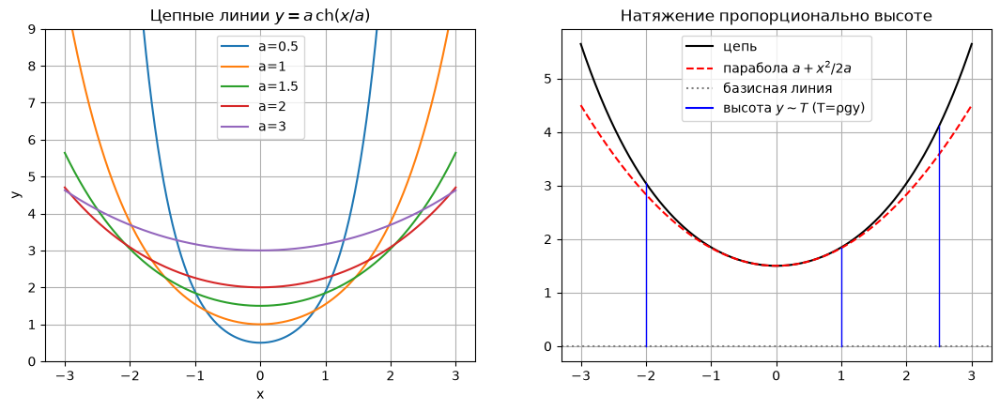

In [7]:
# Проверка: численное решение ОДУ и свойства кривой
a = 1.5
sol = solve_ivp(lambda x,s:[s[1],np.sqrt(1+s[1]**2)/a],[0,3],[a,0],rtol=1e-11,atol=1e-12,dense_output=True)
xs = np.linspace(0,3,40)
assert np.abs(sol.sol(xs)[0]-a*np.cosh(xs/a)).max()<1e-8
s_num = quad(lambda x:np.sqrt(1+np.sinh(x/a)**2),0,2)[0]
assert np.isclose(s_num,a*np.sinh(2/a))
print('формула y=a·ch(x/a) и длина дуги подтверждены численно')

def sag_param(span,length):
    '''a для цепи заданной длины между опорами на одной высоте.'''
    return brentq(lambda a:2*a*np.sinh(span/(2*a))-length,span/40,1e4)

fig,axs = plt.subplots(1,2,figsize=(13,4.6))
x = np.linspace(-3,3,400)
for a_ in [.5,1,1.5,2,3]:
    axs[0].plot(x,a_*np.cosh(x/a_),label=f'a={a_}')
axs[0].set_ylim(0,9); axs[0].set_title('Цепные линии $y=a\\,$ch$(x/a)$'); axs[0].legend(); axs[0].grid(True); axs[0].set_xlabel('x'); axs[0].set_ylabel('y')
a_ = 1.5; y = a_*np.cosh(x/a_)
axs[1].plot(x,y,'k',label='цепь'); axs[1].plot(x,1.5+x**2/(2*1.5),'r--',label='парабола $a+x^2/2a$')
axs[1].axhline(0,color='gray',ls=':',label='базисная линия')
for x0 in [-2,1,2.5]:
    y0 = a_*np.cosh(x0/a_); axs[1].plot([x0,x0],[0,y0],'b',lw=1)
axs[1].plot([],[],'b',label='высота $y\\sim T$ (T=ρgy)'); axs[1].legend(); axs[1].grid(True); axs[1].set_title('Натяжение пропорционально высоте')
fig.savefig('fig/Sol_3_3.png',dpi=130,bbox_inches='tight'); plt.show()

In [8]:
# Анимация: изменение a (то есть H/ρg) и силы на элементах цепи
vals = np.r_[np.geomspace(2.5,20,35),np.geomspace(20,2.5,35)]
x = np.linspace(-3,3,300); xm = np.array([-2.2,-1.1,0,1.1,2.2]); RHO = 1.
fig,ax = plt.subplots(figsize=(6.5,5))
line, = ax.plot([],[],'k',lw=2); q = None
ax.set_xlim(-3.8,3.8); ax.set_ylim(-1.6,2.); ax.grid(True); ax.set_xlabel('x'); ax.set_ylabel('y')
txt = ax.text(.02,.93,'',transform=ax.transAxes,fontsize=9)
ax.plot([],[],'r',label='натяжение T'); ax.plot([],[],'b',label='вес участка'); ax.legend(loc='lower right',fontsize=8)
quiv = [ax.quiver(xm,xm*0,xm*0,xm*0,color=c,angles='xy',scale_units='xy',scale=sc,width=.006) for c,sc in (('r',150),('b',150))]
def update(i):
    a = vals[i]; f = lambda t:a*np.cosh(t/a)-a*np.cosh(3/a)+1.2       # концы закреплены на высоте 1.2
    line.set_data(x,f(x)); ym = f(xm); th = np.arctan(np.sinh(xm/a))
    T = RHO*G*a*np.cosh(xm/a)
    quiv[0].set_offsets(np.c_[xm,ym]); quiv[0].set_UVC(T*np.cos(th),T*np.sin(th))   # натяжение
    quiv[1].set_offsets(np.c_[xm,ym]); quiv[1].set_UVC(0*xm,-RHO*G*np.ones(5)*3)    # вес участка (в масштабе)
    txt.set_text(f'a=H/(ρg)={a:.2f}, H={RHO*G*a:.1f} Н, провисание={a*np.cosh(3/a)-a:.2f}')
show_anim(fig,update,len(vals),'Sol_3_3')

## 3.4. Таутохрона
**Постановка.** Ось $y$ направлена вверх, нижняя точка кривой — $y=0$. Точка стартует без скорости с высоты $h$. Из закона сохранения энергии $v=\sqrt{2g(h-y)}$, а $v=-ds/dt$. Обозначим $\varphi(y)=ds/dy$. Время спуска:
$$T(h)=\int_0^h\frac{\varphi(y)\,dy}{\sqrt{2g(h-y)}}.$$
Требуем $T(h)=T_0$ для всех $h$. Это **интегральное уравнение Абеля**.

**Решение.** Умножим обе части на $\dfrac{1}{\sqrt{u-h}}$ и проинтегрируем по $h$ от $0$ до $u$. Меняя порядок интегрирования и учитывая $\displaystyle\int_y^u\frac{dh}{\sqrt{(u-h)(h-y)}}=\pi$, получаем
$$\frac{\pi}{\sqrt{2g}}\int_0^u\varphi(y)\,dy=T_0\int_0^u\frac{dh}{\sqrt{u-h}}=2T_0\sqrt u.$$
Дифференцируем по $u$:
$$\varphi(y)=\frac{ds}{dy}=\frac{\sqrt{2g}\,T_0}{\pi\sqrt y}=\sqrt{\frac{2a}{y}},\qquad a=\frac{gT_0^2}{\pi^2}.$$

**Циклоида.** Так как $ds^2=dx^2+dy^2$, имеем $\dfrac{dx}{dy}=\sqrt{\dfrac{2a}{y}-1}$. Подстановка $y=a(1-\cos\theta)$ даёт $dy=a\sin\theta\,d\theta$ и $\dfrac{2a}{y}-1=\dfrac{1+\cos\theta}{1-\cos\theta}$, откуда $dx=a(1+\cos\theta)\,d\theta$. Итак,
$$\boxed{\,x=a(\theta+\sin\theta),\quad y=a(1-\cos\theta),\quad \theta\in[-\pi,\pi]\,}.$$

**Независимость времени от старта.** Длина дуги от нижней точки $s=\int\sqrt{2a/y}\,dy=2\sqrt{2ay}=4a\sin(\theta/2)$. Значит, $y=s^2/(8a)$. Уравнение движения вдоль кривой:
$$\ddot s=-g\frac{dy}{ds}=-\frac{g}{4a}s.$$
Это гармонический осциллятор с частотой $\omega=\sqrt{g/(4a)}$, период которого не зависит от амплитуды. Время до нижней точки — четверть периода:
$$T_0=\frac{\pi}{2\omega}=\pi\sqrt{\frac ag}.$$

θ0=0.2: T=1.003033, теория 1.003033
θ0=0.8: T=1.003033, теория 1.003033
θ0=1.5: T=1.003033, теория 1.003033
θ0=2.5: T=1.003033, теория 1.003033
θ0=3.0: T=1.003033, теория 1.003033


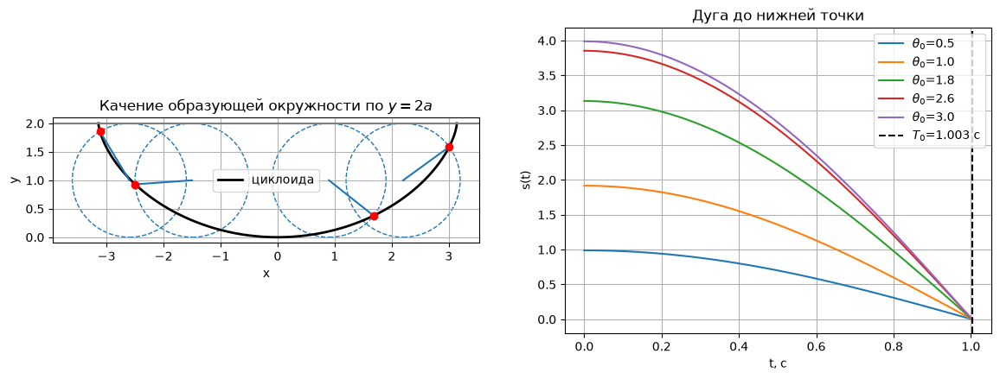

In [9]:
a = 1.0; T0 = np.pi*np.sqrt(a/G)

def descent_time(theta0):
    '''Время спуска прямым интегрированием t=∫ds/v по циклоиде.'''
    h = a*(1-np.cos(theta0))
    # интеграл по θ от 0 до θ0: ds=2a cos(θ/2)dθ, v=√(2g(h-y))
    f = lambda th:2*a*np.cos(th/2)/np.sqrt(2*G*a*(np.cos(th)-np.cos(theta0)))
    return quad(f,0,theta0,limit=200)[0]

for th in [.2,.8,1.5,2.5,3.0]:
    t = descent_time(th); print(f'θ0={th:.1f}: T={t:.6f}, теория {T0:.6f}')
    assert abs(t-T0)<1e-5

th = np.linspace(-np.pi,np.pi,400); X,Y = a*(th+np.sin(th)),a*(1-np.cos(th))
fig,axs = plt.subplots(1,2,figsize=(14,4.6))
axs[0].plot(X,Y,'k',lw=2,label='циклоида')
for t0 in [-2.6,-1.5,.9,2.2]:     # окружность катится под прямой y=2a, её центр равен (a·θ, a)
    cx = a*t0
    px,py = a*(t0+np.sin(t0)),a*(1-np.cos(t0))
    axs[0].add_patch(plt.Circle((cx,a),a,fill=False,color='C0',ls='--')); axs[0].plot([cx,px],[a,py],'C0'); axs[0].plot(px,py,'ro')
axs[0].axhline(2*a,color='gray'); axs[0].set_aspect('equal'); axs[0].grid(True); axs[0].legend(); axs[0].set_title('Качение образующей окружности по $y=2a$'); axs[0].set_xlabel('x'); axs[0].set_ylabel('y')
# Закон движения с разных высот: все приходят в 0 одновременно
t = np.linspace(0,T0,200); w = np.sqrt(G/(4*a))
for th0 in [.5,1.,1.8,2.6,3.]:
    s0 = 4*a*np.sin(th0/2); axs[1].plot(t,s0*np.cos(w*t),label=f'$θ_0$={th0}')
axs[1].axvline(T0,color='k',ls='--',label=f'$T_0$={T0:.3f} c'); axs[1].set_xlabel('t, c'); axs[1].set_ylabel('s(t)'); axs[1].grid(True); axs[1].legend(); axs[1].set_title('Дуга до нижней точки')
fig.savefig('fig/Sol_3_4.png',dpi=130,bbox_inches='tight'); plt.show()

In [10]:
th0s = np.array([.5,1.2,2.,2.6,3.05]); w = np.sqrt(G/(4*a)); S0 = 4*a*np.sin(th0s/2)
tf = np.linspace(0,T0,50)
fig,ax = plt.subplots(figsize=(7,4.2))
ax.plot(X,Y,'k'); dots = ax.scatter(a*(th0s+np.sin(th0s)),a*(1-np.cos(th0s)),c=range(5),cmap='tab10',s=60,zorder=3)
circ = plt.Circle((0,a),a,fill=False,color='C0',ls='--'); ax.add_patch(circ); rad, = ax.plot([],[],'C0'); gp, = ax.plot([],[],'m.',ms=8)
ax.axhline(2*a,color='gray'); ax.set_aspect('equal'); ax.grid(True); ax.set_xlim(-3.5,3.5); ax.set_ylim(-.2,2.6)
txt = ax.text(.02,.91,'',transform=ax.transAxes)
gen = np.linspace(-np.pi,np.pi,len(tf))
def update(i):
    th = 2*np.arcsin(np.clip(S0*np.cos(w*tf[i])/(4*a),-1,1))
    dots.set_offsets(np.c_[a*(th+np.sin(th)),a*(1-np.cos(th))])
    g = gen[i]; circ.center=(a*g,a); px,py = a*(g+np.sin(g)),a*(1-np.cos(g))
    rad.set_data([a*g,px],[a,py]); gp.set_data([px],[py])
    txt.set_text(f't={tf[i]:.3f} c из $T_0$={T0:.3f} c')
show_anim(fig,update,len(tf),'Sol_3_4',interval=70)

## 3.5. Математический маятник
**Уравнение движения.** Масса $m$ на стержне длины $L$, $\theta$ — угол от нижнего положения. Проекция второго закона Ньютона на касательную: $mL\ddot\theta=-mg\sin\theta$, то есть
$$\ddot\theta+\omega_0^2\sin\theta=0,\qquad\omega_0^2=\frac gL.$$

**Линеаризация.** При малых углах $\sin\theta\approx\theta$: $\theta(t)=\theta_0\cos\omega_0t$, $T_0=2\pi/\omega_0$ не зависит от амплитуды.

**Точное решение.** Умножая уравнение на $\dot\theta$ и интегрируя, получаем интеграл энергии:
$$E=\frac{\dot\theta^2}{2}-\omega_0^2\cos\theta=\text{const}.$$
При колебаниях с амплитудой $\theta_0$: $\dot\theta^2=2\omega_0^2(\cos\theta-\cos\theta_0)$. Период равен
$$T=4\int_0^{\theta_0}\frac{d\theta}{\omega_0\sqrt{2(\cos\theta-\cos\theta_0)}}.$$
Замена $\sin(\theta/2)=k\sin\psi$, $k=\sin(\theta_0/2)$ приводит к полному эллиптическому интегралу первого рода:
$$T=\frac{4}{\omega_0}K(k),\qquad K(k)=\int_0^{\pi/2}\frac{d\psi}{\sqrt{1-k^2\sin^2\psi}}.$$
При малых амплитудах $T\approx T_0\left(1+\dfrac{\theta_0^2}{16}\right)$. При $\theta_0\to\pi$ период стремится к бесконечности.

**Фазовый портрет.** Особые точки: $\theta=2\pi k$ — центры, $\theta=\pi+2\pi k$ — сёдла. Сепаратриса проходит через сёдла и соответствует $E=\omega_0^2$:
$$\dot\theta=\pm2\omega_0\cos\frac\theta2.$$
Внутри сепаратрисы маятник колеблется, снаружи вращается.

θ0=0.1: численно 2.0073212, через K(k) 2.0073212, линейная 2.0060667
θ0=1.0: численно 2.1391376, через K(k) 2.1391376, линейная 2.0060667
θ0=2.0: численно 2.6658709, через K(k) 2.6658709, линейная 2.0060667
θ0=3.0: численно 5.1580668, через K(k) 5.1580668, линейная 2.0060667


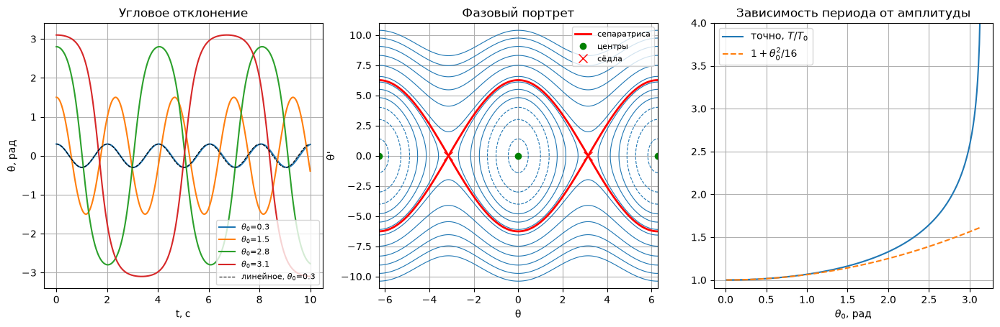

In [11]:
L = 1.0; w0 = np.sqrt(G/L); T_lin = 2*np.pi/w0
rhs = lambda t,s:[s[1],-w0**2*np.sin(s[0])]

def period_numeric(th0):
    '''Период как четыре времени до первого прохождения θ=0.'''
    ev = lambda t,s:s[0]
    ev.terminal,ev.direction = True,-1
    sol = solve_ivp(rhs,[0,100],[th0,0],events=ev,rtol=1e-11,atol=1e-12)
    return 4*sol.t_events[0][0]

for th0 in [.1,1.,2.,3.]:
    Tn,Te = period_numeric(th0),4/w0*ellipk(np.sin(th0/2)**2)   # scipy: аргумент m=k²
    print(f'θ0={th0}: численно {Tn:.7f}, через K(k) {Te:.7f}, линейная {T_lin:.7f}')
    assert abs(Tn-Te)<1e-6

fig,axs = plt.subplots(1,3,figsize=(17,4.8))
t = np.linspace(0,10,1000)
for th0 in [.3,1.5,2.8,3.1]:
    s = solve_ivp(rhs,[0,10],[th0,0],t_eval=t,rtol=1e-9,atol=1e-10)
    axs[0].plot(t,s.y[0],label=f'$θ_0$={th0}')
axs[0].plot(t,.3*np.cos(w0*t),'k--',lw=.8,label='линейное, $θ_0$=0.3'); axs[0].set_xlabel('t, c'); axs[0].set_ylabel('θ, рад'); axs[0].legend(fontsize=8); axs[0].grid(True); axs[0].set_title('Угловое отклонение')
th,om = np.meshgrid(np.linspace(-2*np.pi,2*np.pi,500),np.linspace(-11,11,500))
E = om**2/2-w0**2*np.cos(th)
axs[1].contour(th,om,E,levels=np.r_[np.linspace(-.9,.9,6),np.linspace(1.2,4.5,6)]*w0**2,colors='C0',linewidths=.8)
sx = np.linspace(-2*np.pi,2*np.pi,500)
axs[1].plot(sx,2*w0*np.cos(sx/2),'r',lw=2,label='сепаратриса'); axs[1].plot(sx,-2*w0*np.cos(sx/2),'r',lw=2)
axs[1].plot([-2*np.pi,0,2*np.pi],[0,0,0],'go',label='центры'); axs[1].plot([-np.pi,np.pi],[0,0],'rx',ms=9,label='сёдла')
axs[1].set_xlabel('θ'); axs[1].set_ylabel("θ'"); axs[1].legend(loc='upper right',fontsize=8); axs[1].grid(True); axs[1].set_title('Фазовый портрет')
amps = np.linspace(.01,3.13,300)
axs[2].plot(amps,4/w0*ellipk(np.sin(amps/2)**2)/T_lin,label='точно, $T/T_0$'); axs[2].plot(amps,1+amps**2/16,'--',label='$1+θ_0^2/16$')
axs[2].set_ylim(.9,4); axs[2].set_xlabel('$θ_0$, рад'); axs[2].legend(); axs[2].grid(True); axs[2].set_title('Зависимость периода от амплитуды')
fig.savefig('fig/Sol_3_5.png',dpi=120,bbox_inches='tight'); plt.show()

In [12]:
# Анимация: маятник и фазовая плоскость; сравнение с линейным приближением при большой амплитуде
th0 = 2.6; tf = np.linspace(0,2.2*4/w0*ellipk(np.sin(th0/2)**2)/2,90)
s = solve_ivp(rhs,[0,tf[-1]],[th0,0],t_eval=tf,rtol=1e-9,atol=1e-10); TH,OM = s.y
lin = th0*np.cos(w0*tf)
fig,(a1,a2) = plt.subplots(1,2,figsize=(10,4.3))
a1.set_xlim(-1.3,1.3); a1.set_ylim(-1.3,1.3); a1.set_aspect('equal'); a1.grid(True); a1.set_title('Нелинейный и гармонический маятники')
rod, = a1.plot([],[],'k-o',lw=2,label='нелинейный'); rodl, = a1.plot([],[],'-o',color='C1',alpha=.6,label='гармонический'); a1.legend(loc='lower right',fontsize=8)
txt = a1.text(.02,.93,'',transform=a1.transAxes)
a2.plot(sx,2*w0*np.cos(sx/2),'r',lw=1); a2.plot(sx,-2*w0*np.cos(sx/2),'r',lw=1)
a2.plot(TH,OM,color='gray',lw=.8); pt, = a2.plot([],[],'bo'); a2.set_xlim(-np.pi-.3,np.pi+.3); a2.set_ylim(-7,7); a2.grid(True); a2.set_xlabel('θ'); a2.set_ylabel("θ'"); a2.set_title('Фазовая плоскость')
def update(i):
    rod.set_data([0,L*np.sin(TH[i])],[0,-L*np.cos(TH[i])]); rodl.set_data([0,L*np.sin(lin[i])],[0,-L*np.cos(lin[i])])
    pt.set_data([TH[i]],[OM[i]]); txt.set_text(f't={tf[i]:.2f} c, θ={TH[i]:.2f}')
show_anim(fig,update,len(tf),'Sol_3_5')

In [13]:
# Анимация: переход от гармонических к нелинейным колебаниям при росте амплитуды
amps = np.linspace(.2,3.05,45); T = np.linspace(0,6,300)
fig,ax = plt.subplots(figsize=(7,3.8))
lnl, = ax.plot([],[],label='точное решение'); lhn, = ax.plot([],[],'--',label='$θ_0\\cos ω_0t$'); ax.set_xlim(0,6); ax.set_ylim(-3.3,3.3); ax.grid(True); ax.legend(loc='upper right'); ax.set_xlabel('t, c'); ax.set_ylabel('θ')
txt = ax.text(.02,.9,'',transform=ax.transAxes)
sols = [solve_ivp(rhs,[0,6],[A,0],t_eval=T,rtol=1e-8,atol=1e-9).y[0] for A in amps]
def update(i):
    lnl.set_data(T,sols[i]); lhn.set_data(T,amps[i]*np.cos(w0*T))
    txt.set_text(f'$θ_0$={amps[i]:.2f}, $T/T_0$={4/w0*ellipk(np.sin(amps[i]/2)**2)/T_lin:.3f}')
show_anim(fig,update,len(amps),'Sol_3_5_amp')